# Heat met by sector and country: old vs new fleet sweep

Compares the maximum-savings and maximum-heat operating points (Methods, Eqs. maxheat and maxsav) between

* **old**: fleet sweep of 2026-10-26 (archived in `archive/2026-11-13_old_multiband_analysis/`), and
* **new**: fleet sweep of 2026-11-16/17 on EC2 at commit `13a1b20` (`s3://annaiecc/facility_IHB_potential/results/2026-11-17_fleet_sweep_13a1b20/`).

Both are swept at availability floors 10–100% for the 5 km and 15 km buffers. The operating points are selected here with the same rules for both runs.

**What changed between the two runs**

| Change | Date / commit | Can be separated here? |
|---|---|---|
| Heat demand and band split rebuilt (Hotmaps recipes, food scaled to JRC-IDEES-2023): 522.3 → 535.6 TWh | 2026-11-11, `45d2afe` | yes (demand effect) |
| Gas heat benchmark on net calorific basis (country values change by about ±1–3 €/MWh vs the old run) | 2026-11-11 | yes (gas effect) |
| Heat pump costs from DEA 2026 (higher, +22% below 100 °C, +72% at 100–200 °C), PV system loss 14%, PV VOM, GBR costs | 2026-11-05 to 11-14 | no, inside the coverage effect |
| Land: independent buffers (July 2026) → heat-weighted shared buffers, WDPA pinned to 2026-07, German landscape protection areas eligible | 2026-11-14, `e3d6ca2` | partly, via land ratio per site |
| 16 independent representative days → one linked 8,760-h year | committed 2026-11-14, `f746f3f` | no, inside the coverage effect |
| Storage discharge rating capped at the load (storage ≤ 20 h / 4 h of load) | 2026-11-15, `e9b30a6` | no, inside the coverage effect |
| Solver timeouts rejected, interior point | 2026-11-15, `fbd7357` | yes (failed solves) |

## Findings (computed below)

**Fleet.** Heat met fell by 4.7 to 8.1 percentage points in all four scenarios, while fleet LCOH stayed within about €1/MWh.

| Scenario | Old heat met | New heat met | Change | Old LCOH | New LCOH |
|---|---|---|---|---|---|
| 5 km, max savings | 277.9 TWh (53.2%) | 248.1 TWh (46.3%) | −6.9 pp | 38.7 | 39.5 |
| 5 km, max heat | 305.8 TWh (58.5%) | 270.2 TWh (50.5%) | −8.1 pp | 50.2 | 49.1 |
| 15 km, max savings | 377.1 TWh (72.2%) | 361.4 TWh (67.5%) | −4.7 pp | 39.9 | 39.7 |
| 15 km, max heat | 433.7 TWh (83.0%) | 410.1 TWh (76.6%) | −6.5 pp | 55.9 | 54.9 |

**What drove it** (15 km max heat, change −23.6 TWh):

1. **Storage duration cap, the main driver.** The share met by heat-pump and mixed sites fell by about 21–34 pp (heat-pump-only 89% → 55%, mixed 88% → 67%), worth −44 TWh. At the old operating points the median Li-ion store held 14–17 h of the heat pumps' electric load, because the old 4 h limit could be bypassed by buying unused discharge rating. The new run holds it at 4 h, so these sites can no longer carry solar through the night. Land binds at almost none of these sites (0–21% of their demand), so lost land does not explain it. This is why food (−32 pp), textiles (−33 pp), pulp and paper (−36 pp) and aluminium (−10 pp) drop, and why the single-site tests found max heat falling from 90% to 50% once the cap was added.
2. **Heat demand rebuild, +10.7 TWh.** Demand rose from 522.3 to 535.6 TWh. Glass (+19 TWh demand), steel (+17), cement (+11) and chemicals (+6) gained, while steam cracking (−25), food (−8) and pulp and paper (−6) fell. At the old shares this adds served heat, mainly in glass, steel and cement.
3. **Land, a secondary driver for heat-battery sites.** Heat-battery-only sites (two thirds of demand) slightly improved their share met at 15 km (80.5% → 83.0%, +8.8 TWh), even though land binds more often (27% → 42% of their demand). Sites that lost more than half their land lost more share met (−15 pp) than sites whose land stayed the same (−6 pp). The 5 km buffer leaves steel and steam cracking land-limited in both runs.
4. **Gas benchmark, negligible** (+0.4 to +0.9 TWh). The net-calorific benchmark is within about €0.5–3/MWh of the values used in the old run.
5. **Failed solves, none.** The 10 sites that failed at 5 km have no eligible land within 5 km. They served 0% in the old run too, so they change nothing.

**By country.** Countries with much food, textile or other heat-pump heat lose most: France −12.8 pp, Sweden −14.5 pp, Spain −10.9 pp and Italy −9.5 pp at 15 km max heat. Germany (−2.7 pp) and Austria (−2.6 pp) barely move because steel and other heat-battery heat dominate their demand.

**Not separated here.** The DEA heat pump costs, the PV loss and the move from 16 representative days to the linked year are all inside the share-met term. The single-site tests at the end show that the cost changes alone raise heat pump LCOH by about 5% at low availability, which is small next to the storage cap.

In [1]:
import io, subprocess, tarfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 80)

ROOT = Path.cwd()
while not (ROOT / "run_multiband_potential.py").exists():
    ROOT = ROOT.parent
AN = ROOT / "outputs" / "multiband" / "analysis"
OLD_COMMIT = "785ecfd"   # inputs used by the 2026-10-26 sweep (site assessment, gas costs)
OLD_TAR = ROOT / "archive/2026-11-13_old_multiband_analysis/multiband_analysis_old_outputs.tar.gz"
OLD_S3 = "facility_IHB_potential/archive/2026-11-13_old_multiband_analysis/multiband_analysis_old_outputs.tar.gz"
NEW_S3 = "facility_IHB_potential/results/2026-11-17_fleet_sweep_13a1b20/sweep_results_2026-11-17.tar.gz"
BUCKET = "annaiecc"
KMS = (5, 15)
OLD_C, NEW_C, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"   # validated pair (CVD dE 24.7)

In [2]:
def git_csv(commit, path):
    txt = subprocess.check_output(["git", "-C", str(ROOT), "show", f"{commit}:{path}"], text=True)
    return pd.read_csv(io.StringIO(txt), low_memory=False)

def fetch_s3(key, dest):
    import boto3
    dest.parent.mkdir(parents=True, exist_ok=True)
    boto3.client("s3").download_file(BUCKET, key, str(dest))

def extract_sweeps(tar_path, cache):
    # Per-site sweep CSVs (lcoh_vs_availability_<id>_<km>km.csv) from a results tarball.
    if cache.exists() and any(cache.rglob("lcoh_vs_availability_*km.csv")):
        return cache
    with tarfile.open(tar_path) as t:
        members = [m for m in t.getmembers()
                   if Path(m.name).name.startswith("lcoh_vs_availability_")
                   and Path(m.name).stem.split("_")[-2].isdigit()]
        t.extractall(cache, members=members, filter="data")
    return cache

def per_site_dir(kind):
    if kind == "new":
        if len(list(AN.glob("lcoh_vs_availability_*_15km.csv"))) >= 2000:
            return AN
        tar = AN / "_cache_new_sweeps" / "sweep_results.tar.gz"
        if not tar.exists():
            fetch_s3(NEW_S3, tar)
        return extract_sweeps(tar, AN / "_cache_new_sweeps" / "files")
    tar = OLD_TAR
    if not tar.exists():
        tar = AN / "_cache_old_sweeps" / "old.tar.gz"
        fetch_s3(OLD_S3, tar)
    return extract_sweeps(tar, AN / "_cache_old_sweeps" / "files")

def load_sweeps(kind, km):
    d = per_site_dir(kind)
    # Live folder: top level only (the caches below it hold the other run). Cache folders: recursive.
    found = d.glob(f"lcoh_vs_availability_*_{km}km.csv") if d == AN else d.rglob(f"lcoh_vs_availability_*_{km}km.csv")
    files = [f for f in found if f.stem.split("_")[-2].isdigit()]
    assert len(files) == len({f.name for f in files}), "duplicate per-site files"
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    ok = df[df["status"] == "ok"].copy()
    ok["floor"] = ok["availability_floor"].round(2)
    ok["served"] = ok["replaceable_heat_mwh_th"] * ok["Reliability_%"] / 100
    ok["lcoh"] = ok["LCOH_served_eur_perMWh"]
    return ok, df["source_id"].nunique()

def gas_map(df):
    m = df.set_index("iso3")["gas_heat_cost_eur_mwh"].to_dict()
    m["GBR"] = m["IRL"]   # the UK uses the Irish value (gas_benchmark.country_gas_heat)
    return m

GAS_PATH = "Input/industrial_heat_pump_costs/eu_heat_pump_costs_by_country.csv"
GAS = {"old": gas_map(git_csv(OLD_COMMIT, GAS_PATH)), "new": gas_map(pd.read_csv(ROOT / GAS_PATH))}
BANDS = ["heat_below100C_tj", "heat_100C-200C_tj", "heat_200C-500C_tj", "heat_500C-1000C_tj", "heat_above1000C_tj"]
def sites(a):
    a = a[a["has_solar_data"] & a["has_replaceable_heat"]].copy()
    tot = a[BANDS].sum(axis=1)
    a["hp_share"] = a[BANDS[:2]].sum(axis=1) / tot
    a["lt_share"], a["mt_share"] = a[BANDS[0]] / tot, a[BANDS[1]] / tot
    return a[["source_id", "source_name", "subsector", "iso3_country", "replaceable_heat_mwh_th", "hp_share", "lt_share", "mt_share"]]
SITES = {"old": sites(git_csv(OLD_COMMIT, "outputs/eu_ihb_site_assessment_2024.csv")),
         "new": sites(pd.read_csv(ROOT / "outputs/eu_ihb_site_assessment_2024.csv", low_memory=False))}
SWEEPS = {(k, km): load_sweeps(k, km) for k in ("old", "new") for km in KMS}
import sys as _sys; print("python", _sys.executable)
for (k, km), (d, n) in SWEEPS.items():
    assert len(d) <= 10 * n, f"{k} {km} km: more ok rows than 10 per site"
    print(f"{k:3s} {km:>2} km: {n} sites swept, {d.source_id.nunique()} with >=1 ok floor, {len(d)} ok rows")
print({k: round(v.replaceable_heat_mwh_th.sum() / 1e6, 1) for k, v in SITES.items()}, "TWh demand")

python /Users/annayuen/Desktop/IECC/industrial_decarb/facility_IHB_potential/.venv/bin/python
old  5 km: 2192 sites swept, 2192 with >=1 ok floor, 21920 ok rows
old 15 km: 2192 sites swept, 2192 with >=1 ok floor, 21920 ok rows
new  5 km: 2192 sites swept, 2182 with >=1 ok floor, 21820 ok rows
new 15 km: 2192 sites swept, 2192 with >=1 ok floor, 21915 ok rows
{'old': np.float64(522.3), 'new': np.float64(535.6)} TWh demand


## Operating points

Same rules for both runs (Methods): **max heat** is the highest floor with LCOH ≤ the country gas heat cost. **Max savings** maximises served × (gas − LCOH) over the floors with LCOH ≤ gas. A site with no such floor serves no heat. A site whose solves all failed serves no heat and is counted as demand.

In [3]:
def operating_points(kind, km, gas_kind):
    d, _ = SWEEPS[(kind, km)]
    s = SITES[kind].copy()
    g = d["iso3_country"].map(GAS[gas_kind])
    below = d[d["lcoh"] <= g].copy()
    below["saving"] = below["served"] * (below["iso3_country"].map(GAS[gas_kind]) - below["lcoh"])
    mh = below.loc[below.groupby("source_id")["floor"].idxmax()]
    ms = below.loc[below.groupby("source_id")["saving"].idxmax()]
    for tag, p in (("heat", mh), ("sav", ms)):
        p = p.set_index("source_id")
        s[f"served_{tag}"] = s["source_id"].map(p["served"]).fillna(0.0)
        s[f"lcoh_{tag}"] = s["source_id"].map(p["lcoh"])
        s[f"floor_{tag}"] = s["source_id"].map(p["floor"])
        for col in ("S_opt_MW", "liion_energy_MWh", "ihb_energy_MWh", "total_load_MW"):
            s[f"{col}_{tag}"] = s["source_id"].map(p[col])
    s["solved"] = s["source_id"].isin(d["source_id"])
    s["land_km2"] = s["source_id"].map(d.groupby("source_id")["available_land_km2"].first())
    s["max_served_pct"] = s["source_id"].map(d.groupby("source_id")["Reliability_%"].max())
    return s

OP = {(k, km, gk): operating_points(k, km, gk)
      for km in KMS for (k, gk) in (("old", "old"), ("old", "new"), ("new", "new"))}

def agg(df, tag, by=None):
    f = lambda t: pd.Series({
        "demand_TWh": t["replaceable_heat_mwh_th"].sum() / 1e6,
        "served_TWh": t[f"served_{tag}"].sum() / 1e6,
        "served_pct": 100 * t[f"served_{tag}"].sum() / t["replaceable_heat_mwh_th"].sum(),
        "LCOH": (t[f"lcoh_{tag}"].fillna(0) * t[f"served_{tag}"]).sum() / max(t[f"served_{tag}"].sum(), 1e-9)})
    return f(df) if by is None else df.groupby(by).apply(f, include_groups=False)

rows = []
for km in KMS:
    for tag, name in (("sav", "max savings"), ("heat", "max heat")):
        o, n = agg(OP[("old", km, "old")], tag), agg(OP[("new", km, "new")], tag)
        rows.append({"scenario": f"{km} km {name}", "old_TWh": o.served_TWh, "new_TWh": n.served_TWh,
                     "old_%": o.served_pct, "new_%": n.served_pct, "change_pp": n.served_pct - o.served_pct,
                     "old_LCOH": o.LCOH, "new_LCOH": n.LCOH})
fleet = pd.DataFrame(rows).set_index("scenario")
print("Fleet: old demand 522.3 TWh, new demand 535.6 TWh. LCOH in EUR/MWh weighted by heat served.")
fleet.round(1)

Fleet: old demand 522.3 TWh, new demand 535.6 TWh. LCOH in EUR/MWh weighted by heat served.


,old_TWh,new_TWh,old_%,new_%,change_pp,old_LCOH,new_LCOH
scenario,,,,,,,
5 km max savings,277.9,248.1,53.2,46.3,-6.9,38.7,39.5
5 km max heat,305.8,270.2,58.5,50.5,-8.1,50.2,49.1
15 km max savings,377.1,361.4,72.2,67.5,-4.7,39.9,39.7
15 km max heat,433.7,410.1,83.0,76.6,-6.5,55.9,54.9


## Heat met by sector

In [4]:
def compare(by, tag, km):
    o = agg(OP[("old", km, "old")], tag, by)
    n = agg(OP[("new", km, "new")], tag, by)
    t = pd.DataFrame({"demand_old_TWh": o.demand_TWh, "demand_new_TWh": n.demand_TWh,
                      "old_%": o.served_pct, "new_%": n.served_pct,
                      "change_pp": n.served_pct - o.served_pct,
                      "old_TWh": o.served_TWh, "new_TWh": n.served_TWh,
                      "old_LCOH": o.LCOH, "new_LCOH": n.LCOH})
    return t.sort_values("demand_new_TWh", ascending=False)

for km in KMS:
    for tag, name in (("sav", "max savings"), ("heat", "max heat")):
        print(f"\n=== {km} km, {name}")
        display(compare("subsector", tag, km).round(1))


=== 5 km, max savings


,demand_old_TWh,demand_new_TWh,old_%,new_%,change_pp,old_TWh,new_TWh,old_LCOH,new_LCOH
subsector,,,,,,,,,
petrochemical-steam-cracking,152.3,126.9,29.7,29.9,0.2,45.2,37.9,39.2,36.6
iron-and-steel,101.4,118.0,36.7,35.0,-1.7,37.2,41.2,40.9,36.9
food-beverage-tobacco,98.4,90.4,79.9,50.8,-29.1,78.6,45.9,33.6,45.4
cement,54.1,65.1,68.2,69.3,1.1,36.9,45.1,40.0,35.4
chemicals,43.1,48.7,66.8,57.4,-9.4,28.8,28.0,40.9,38.8
glass,16.3,35.4,70.3,69.3,-1.0,11.4,24.6,41.7,39.1
textiles-leather-apparel,17.7,18.3,83.2,49.7,-33.5,14.7,9.1,35.4,43.8
pulp-and-paper,18.2,12.2,69.0,43.1,-25.9,12.6,5.3,47.9,62.1
lime,10.9,10.3,61.9,65.1,3.2,6.8,6.7,41.1,39.7



=== 5 km, max heat


,demand_old_TWh,demand_new_TWh,old_%,new_%,change_pp,old_TWh,new_TWh,old_LCOH,new_LCOH
subsector,,,,,,,,,
petrochemical-steam-cracking,152.3,126.9,30.1,30.2,0.1,45.8,38.3,40.2,37.7
iron-and-steel,101.4,118.0,39.4,36.7,-2.7,40.0,43.3,48.6,42.8
food-beverage-tobacco,98.4,90.4,89.7,57.9,-31.8,88.2,52.3,49.7,56.6
cement,54.1,65.1,77.4,76.3,-1.0,41.8,49.7,53.4,48.2
chemicals,43.1,48.7,74.9,62.4,-12.4,32.3,30.4,53.0,50.3
glass,16.3,35.4,81.7,77.9,-3.8,13.3,27.6,56.4,54.1
textiles-leather-apparel,17.7,18.3,90.7,57.6,-33.1,16.0,10.5,47.0,53.4
pulp-and-paper,18.2,12.2,77.7,47.8,-29.8,14.2,5.8,65.0,70.9
lime,10.9,10.3,71.5,73.3,1.8,7.8,7.6,57.2,54.3



=== 15 km, max savings


,demand_old_TWh,demand_new_TWh,old_%,new_%,change_pp,old_TWh,new_TWh,old_LCOH,new_LCOH
subsector,,,,,,,,,
petrochemical-steam-cracking,152.3,126.9,68.2,72.7,4.6,103.8,92.3,41.8,39.0
iron-and-steel,101.4,118.0,67.3,71.3,4.0,68.2,84.1,42.1,38.2
food-beverage-tobacco,98.4,90.4,80.7,51.2,-29.5,79.4,46.3,33.6,45.4
cement,54.1,65.1,74.2,78.8,4.6,40.1,51.3,40.1,35.0
chemicals,43.1,48.7,71.4,67.8,-3.6,30.8,33.0,40.6,40.3
glass,16.3,35.4,70.8,71.3,0.4,11.5,25.2,41.7,39.2
textiles-leather-apparel,17.7,18.3,83.4,49.9,-33.5,14.7,9.1,35.5,43.8
pulp-and-paper,18.2,12.2,74.3,44.7,-29.6,13.5,5.5,47.7,61.6
lime,10.9,10.3,68.9,74.1,5.2,7.5,7.7,40.8,39.1



=== 15 km, max heat


,demand_old_TWh,demand_new_TWh,old_%,new_%,change_pp,old_TWh,new_TWh,old_LCOH,new_LCOH
subsector,,,,,,,,,
petrochemical-steam-cracking,152.3,126.9,79.5,83.4,3.9,121.1,105.8,59.6,56.9
iron-and-steel,101.4,118.0,77.9,80.5,2.6,79.0,95.0,56.7,53.3
food-beverage-tobacco,98.4,90.4,90.7,58.4,-32.3,89.2,52.8,49.4,56.6
cement,54.1,65.1,84.8,86.7,1.9,45.9,56.4,54.5,46.2
chemicals,43.1,48.7,83.6,78.4,-5.2,36.0,38.2,57.1,61.4
glass,16.3,35.4,82.5,81.3,-1.2,13.4,28.8,55.9,56.2
textiles-leather-apparel,17.7,18.3,90.9,57.9,-33.0,16.1,10.6,46.5,53.6
pulp-and-paper,18.2,12.2,85.6,50.1,-35.5,15.6,6.1,69.5,70.2
lime,10.9,10.3,82.0,84.3,2.3,8.9,8.7,57.7,54.5


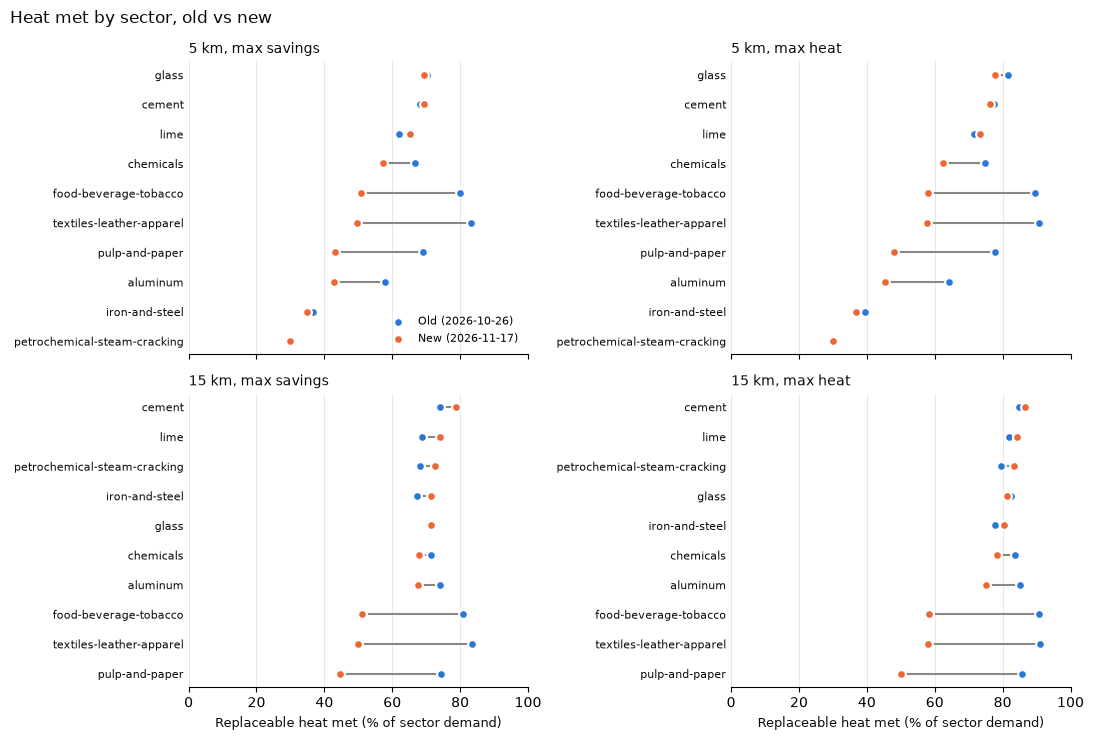

In [5]:
def dumbbell(ax, t, title, label_col="index"):
    t = t.sort_values("new_%")
    y = np.arange(len(t))
    ax.hlines(y, t["old_%"], t["new_%"], color=MUTED, lw=1.5, zorder=1)
    ax.scatter(t["old_%"], y, s=40, color=OLD_C, zorder=2, label="Old (2026-10-26)", edgecolor="white", linewidth=1.5)
    ax.scatter(t["new_%"], y, s=40, color=NEW_C, zorder=3, label="New (2026-11-17)", edgecolor="white", linewidth=1.5)
    ax.set_yticks(y, t.index, fontsize=8, color=INK)
    ax.set_xlim(0, 100)
    ax.set_title(title, fontsize=10, color=INK, loc="left")
    ax.grid(axis="x", color="#e4e3df", lw=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for i, km in enumerate(KMS):
    for j, (tag, name) in enumerate((("sav", "max savings"), ("heat", "max heat"))):
        dumbbell(axes[i, j], compare("subsector", tag, km), f"{km} km, {name}")
for ax in axes[-1]:
    ax.set_xlabel("Replaceable heat met (% of sector demand)", fontsize=9, color=INK)
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Heat met by sector, old vs new", fontsize=12, x=0.01, ha="left", color=INK)
fig.tight_layout()
plt.show()

## Heat met by country

In [6]:
for km in KMS:
    for tag, name in (("sav", "max savings"), ("heat", "max heat")):
        print(f"\n=== {km} km, {name}")
        display(compare("iso3_country", tag, km).round(1))


=== 5 km, max savings


,demand_old_TWh,demand_new_TWh,old_%,new_%,change_pp,old_TWh,new_TWh,old_LCOH,new_LCOH
iso3_country,,,,,,,,,
DEU,119.7,122.7,41.4,40.0,-1.4,49.5,49.1,38.3,44.0
FRA,56.2,55.0,60.1,49.6,-10.5,33.7,27.3,32.2,37.6
ITA,47.7,51.4,72.6,61.6,-11.0,34.6,31.7,31.7,33.6
NLD,47.8,45.2,33.4,27.9,-5.4,16.0,12.6,38.8,43.5
ESP,40.0,43.1,71.6,54.6,-17.0,28.6,23.5,31.3,30.4
POL,30.7,34.2,57.8,52.1,-5.7,17.7,17.8,48.8,44.4
GBR,32.8,32.4,48.8,43.0,-5.8,16.0,13.9,50.2,47.0
BEL,30.4,29.4,39.1,31.3,-7.9,11.9,9.2,38.9,41.8
SWE,15.1,14.9,37.0,25.6,-11.3,5.6,3.8,51.4,56.1



=== 5 km, max heat


,demand_old_TWh,demand_new_TWh,old_%,new_%,change_pp,old_TWh,new_TWh,old_LCOH,new_LCOH
iso3_country,,,,,,,,,
DEU,119.7,122.7,46.4,43.7,-2.6,55.5,53.7,53.7,54.7
FRA,56.2,55.0,65.5,54.5,-11.0,36.8,30.0,43.6,47.5
ITA,47.7,51.4,77.3,66.5,-10.7,36.9,34.2,41.7,42.4
NLD,47.8,45.2,35.4,29.7,-5.7,16.9,13.4,45.8,52.2
ESP,40.0,43.1,75.5,56.8,-18.7,30.2,24.5,39.9,36.9
POL,30.7,34.2,66.5,57.6,-9.0,20.4,19.7,61.7,56.4
GBR,32.8,32.4,55.4,47.6,-7.8,18.2,15.4,60.0,56.2
BEL,30.4,29.4,44.7,36.9,-7.8,13.6,10.9,50.5,49.0
SWE,15.1,14.9,41.0,28.1,-12.9,6.2,4.2,75.8,74.4



=== 15 km, max savings


,demand_old_TWh,demand_new_TWh,old_%,new_%,change_pp,old_TWh,new_TWh,old_LCOH,new_LCOH
iso3_country,,,,,,,,,
DEU,119.7,122.7,65.0,64.6,-0.4,77.8,79.3,39.6,43.9
FRA,56.2,55.0,78.8,67.1,-11.7,44.3,36.9,32.8,36.7
ITA,47.7,51.4,86.4,76.2,-10.1,41.2,39.2,32.1,32.7
NLD,47.8,45.2,71.7,66.7,-5.1,34.3,30.1,43.0,43.2
ESP,40.0,43.1,86.5,78.3,-8.2,34.6,33.8,31.7,29.5
POL,30.7,34.2,65.1,63.0,-2.2,20.0,21.6,49.3,44.7
GBR,32.8,32.4,65.5,59.5,-6.0,21.5,19.3,52.8,46.3
BEL,30.4,29.4,63.8,62.1,-1.7,19.4,18.3,40.4,42.9
SWE,15.1,14.9,64.0,54.4,-9.6,9.7,8.1,52.0,51.7



=== 15 km, max heat


,demand_old_TWh,demand_new_TWh,old_%,new_%,change_pp,old_TWh,new_TWh,old_LCOH,new_LCOH
iso3_country,,,,,,,,,
DEU,119.7,122.7,77.5,74.8,-2.7,92.8,91.8,60.6,62.5
FRA,56.2,55.0,88.9,76.1,-12.8,49.9,41.8,48.1,49.0
ITA,47.7,51.4,92.0,82.5,-9.5,43.9,42.4,43.4,44.8
NLD,47.8,45.2,82.3,77.9,-4.4,39.4,35.2,58.7,64.2
ESP,40.0,43.1,94.3,83.4,-10.9,37.7,36.0,45.8,38.9
POL,30.7,34.2,78.4,73.4,-5.0,24.0,25.1,65.5,63.0
GBR,32.8,32.4,76.7,71.7,-5.0,25.2,23.2,63.7,61.4
BEL,30.4,29.4,81.0,72.0,-9.0,24.6,21.2,58.2,51.0
SWE,15.1,14.9,74.0,59.5,-14.5,11.2,8.9,82.2,71.5


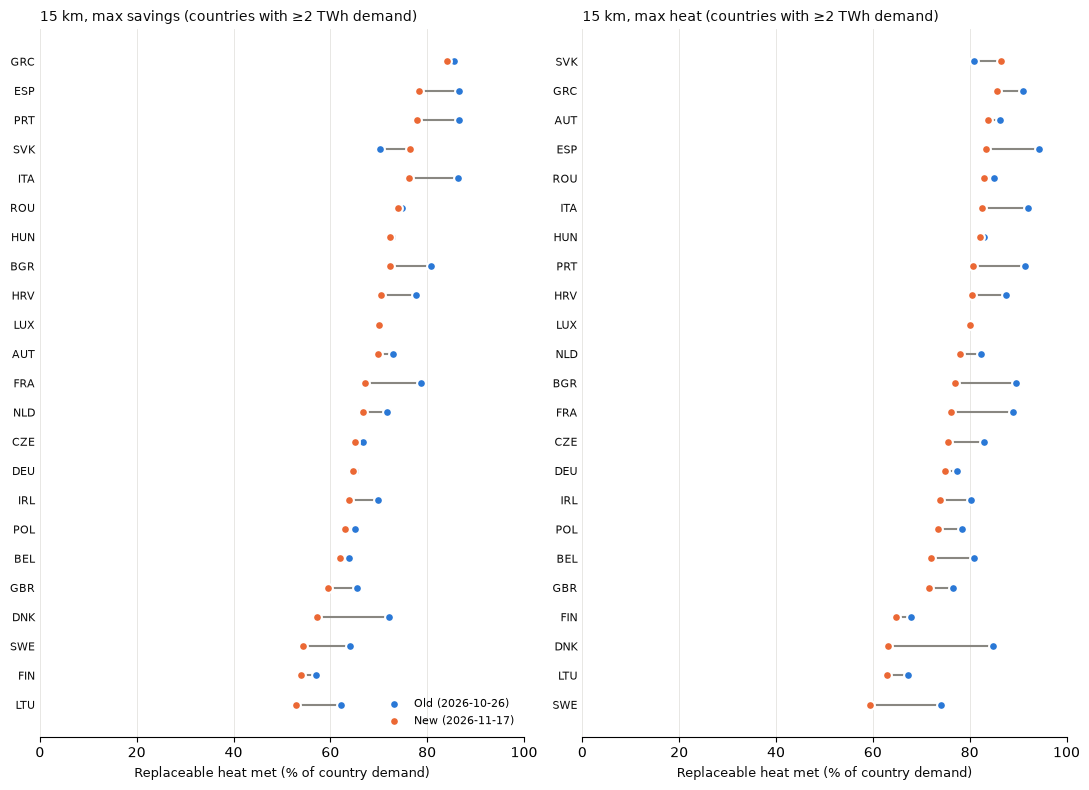

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 8), sharex=True)
for j, (tag, name) in enumerate((("sav", "max savings"), ("heat", "max heat"))):
    t = compare("iso3_country", tag, 15)
    dumbbell(axes[j], t[t["demand_new_TWh"] >= 2], f"15 km, {name} (countries with ≥2 TWh demand)")
    axes[j].set_xlabel("Replaceable heat met (% of country demand)", fontsize=9, color=INK)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

## What led to the change: decomposition

For each site *i*, with demand *D* and share met *c* (served / demand):

* **gas benchmark** = D_old × (c_old,new gas − c_old,old gas): old sweep, re-selected with the new gas costs
* **heat demand** = (D_new − D_old) × c_old,new gas: new demand at the old share met
* **failed solves** = −D_new × c_old,new gas for the sites whose new solves all failed
* **share met (model changes)** = D_new × (c_new − c_old,new gas) for the other sites. It holds land, technology costs, the linked year and the storage cap together.

The four terms add up exactly to the change in TWh served.

In [8]:
def decompose(km, tag, by):
    o = OP[("old", km, "old")].set_index("source_id")
    og = OP[("old", km, "new")].set_index("source_id")
    n = OP[("new", km, "new")].set_index("source_id")
    ids = n.index.union(o.index)
    Do, Dn = o["replaceable_heat_mwh_th"].reindex(ids).fillna(0), n["replaceable_heat_mwh_th"].reindex(ids).fillna(0)
    co = (o[f"served_{tag}"] / o["replaceable_heat_mwh_th"]).reindex(ids).fillna(0)
    cog = (og[f"served_{tag}"] / og["replaceable_heat_mwh_th"]).reindex(ids).fillna(0)
    cn = (n[f"served_{tag}"] / n["replaceable_heat_mwh_th"]).reindex(ids).fillna(0)
    failed = ~n["solved"].reindex(ids).fillna(False).astype(bool)
    comp = pd.DataFrame({
        "gas benchmark": Do * (cog - co),
        "heat demand": (Dn - Do) * cog,
        "failed solves": np.where(failed, -Dn * cog, 0.0),
        "share met (model changes)": np.where(failed, 0.0, Dn * (cn - cog)),
    }, index=ids) / 1e6
    comp["total change"] = comp.sum(axis=1)
    check = (n[f"served_{tag}"].reindex(ids).fillna(0) - o[f"served_{tag}"].reindex(ids).fillna(0)) / 1e6
    assert np.allclose(comp["total change"], check, atol=1e-9)
    key = n[by].reindex(ids).fillna(o[by].reindex(ids))
    return comp.groupby(key).sum().sort_values("total change")

for km in KMS:
    for tag, name in (("sav", "max savings"), ("heat", "max heat")):
        t = decompose(km, tag, "subsector")
        t.loc["FLEET"] = t.sum()
        print(f"\n=== {km} km, {name}: change in TWh served")
        display(t.round(1))


=== 5 km, max savings: change in TWh served


,gas benchmark,heat demand,failed solves,share met (model changes),total change
subsector,,,,,
food-beverage-tobacco,0.0,-6.6,0.0,-26.1,-32.7
petrochemical-steam-cracking,0.0,-7.5,0.0,0.2,-7.3
pulp-and-paper,0.0,-4.1,0.0,-3.2,-7.3
textiles-leather-apparel,0.0,0.5,0.0,-6.1,-5.6
aluminum,0.0,0.1,0.0,-1.6,-1.5
chemicals,0.3,3.9,0.0,-5.0,-0.8
lime,0.0,-0.3,0.0,0.3,-0.0
iron-and-steel,0.0,7.4,0.0,-3.3,4.1
cement,0.1,7.5,0.0,0.6,8.2



=== 5 km, max heat: change in TWh served


,gas benchmark,heat demand,failed solves,share met (model changes),total change
subsector,,,,,
food-beverage-tobacco,0.2,-7.3,0.0,-28.8,-35.9
pulp-and-paper,-0.0,-4.6,0.0,-3.7,-8.3
petrochemical-steam-cracking,0.0,-7.6,0.0,0.1,-7.5
textiles-leather-apparel,0.0,0.5,0.0,-6.1,-5.5
aluminum,0.0,0.2,0.0,-2.1,-1.9
chemicals,0.0,4.3,0.0,-6.1,-1.8
lime,0.0,-0.4,0.0,0.2,-0.2
iron-and-steel,0.0,8.2,0.0,-4.8,3.4
cement,0.2,8.5,0.0,-0.9,7.8



=== 15 km, max savings: change in TWh served


,gas benchmark,heat demand,failed solves,share met (model changes),total change
subsector,,,,,
food-beverage-tobacco,0.0,-6.6,0.0,-26.5,-33.1
petrochemical-steam-cracking,0.0,-17.3,0.0,5.8,-11.5
pulp-and-paper,0.0,-4.5,0.0,-3.6,-8.1
textiles-leather-apparel,0.0,0.5,0.0,-6.2,-5.6
aluminum,0.0,0.0,0.0,-0.6,-0.6
lime,0.0,-0.4,0.0,0.5,0.2
chemicals,0.3,4.2,0.0,-2.2,2.3
cement,0.1,8.2,0.0,2.9,11.2
glass,0.0,13.6,0.0,0.0,13.7



=== 15 km, max heat: change in TWh served


,gas benchmark,heat demand,failed solves,share met (model changes),total change
subsector,,,,,
food-beverage-tobacco,0.2,-7.3,0.0,-29.3,-36.4
petrochemical-steam-cracking,0.0,-20.2,0.0,4.9,-15.3
pulp-and-paper,-0.0,-5.1,0.0,-4.3,-9.5
textiles-leather-apparel,0.0,0.5,0.0,-6.1,-5.5
aluminum,0.0,0.1,0.0,-1.0,-0.9
lime,0.0,-0.5,0.0,0.2,-0.2
chemicals,0.3,4.9,0.0,-3.1,2.2
cement,0.2,9.4,0.0,0.9,10.5
glass,0.0,15.8,0.0,-0.4,15.4


In [9]:
for km in KMS:
    for tag, name in (("sav", "max savings"), ("heat", "max heat")):
        t = decompose(km, tag, "iso3_country")
        t.loc["FLEET"] = t.sum()
        print(f"\n=== {km} km, {name}: change in TWh served by country")
        display(t.round(1))


=== 5 km, max savings: change in TWh served by country


,gas benchmark,heat demand,failed solves,share met (model changes),total change
iso3_country,,,,,
FRA,0.0,-0.3,0.0,-6.1,-6.5
ESP,0.1,2.6,0.0,-7.8,-5.1
NLD,0.0,0.2,0.0,-3.6,-3.3
ITA,0.0,3.1,0.0,-6.1,-3.0
BEL,-0.0,0.5,0.0,-3.2,-2.7
GBR,0.1,0.2,0.0,-2.3,-2.1
SWE,0.0,-0.6,0.0,-1.1,-1.8
AUT,0.1,-0.2,0.0,-1.2,-1.4
IRL,0.0,-0.0,0.0,-1.3,-1.3



=== 5 km, max heat: change in TWh served by country


,gas benchmark,heat demand,failed solves,share met (model changes),total change
iso3_country,,,,,
FRA,0.0,-0.1,0.0,-6.7,-6.8
ESP,0.0,2.8,0.0,-8.5,-5.7
NLD,0.0,0.3,0.0,-3.8,-3.5
GBR,0.1,0.3,0.0,-3.2,-2.8
BEL,0.0,0.8,0.0,-3.5,-2.7
ITA,0.2,3.5,0.0,-6.3,-2.7
SWE,0.0,-0.7,0.0,-1.3,-2.0
DEU,-0.0,3.8,0.0,-5.6,-1.9
AUT,0.0,-0.2,0.0,-1.4,-1.6



=== 15 km, max savings: change in TWh served by country


,gas benchmark,heat demand,failed solves,share met (model changes),total change
iso3_country,,,,,
FRA,0.0,-1.3,0.0,-6.1,-7.4
NLD,0.0,-1.9,0.0,-2.3,-4.2
GBR,0.1,-0.3,0.0,-2.0,-2.2
ITA,0.0,2.8,0.0,-4.8,-2.0
SWE,0.0,-0.2,0.0,-1.3,-1.5
BEL,-0.0,-0.7,0.0,-0.4,-1.1
ESP,0.1,2.6,0.0,-3.5,-0.8
PRT,0.0,0.2,0.0,-0.8,-0.6
FIN,0.0,-0.3,0.0,-0.2,-0.5



=== 15 km, max heat: change in TWh served by country


,gas benchmark,heat demand,failed solves,share met (model changes),total change
iso3_country,,,,,
FRA,0.0,-1.3,0.0,-6.8,-8.1
NLD,0.3,-2.2,0.0,-2.3,-4.2
BEL,0.0,-0.9,0.0,-2.6,-3.5
SWE,0.0,-0.4,0.0,-1.9,-2.3
GBR,0.1,-0.4,0.0,-1.7,-2.0
ESP,0.2,2.8,0.0,-4.7,-1.7
ITA,0.2,3.2,0.0,-4.8,-1.5
DEU,-0.0,2.8,0.0,-3.7,-0.9
PRT,0.0,0.3,0.0,-1.1,-0.8


## Inside the share-met change: land, temperature route and what limits each site

The share-met term mixes four model changes. Grouping sites by how their land and heat changed shows which one dominates.

* **land ratio** = new / old available land (shared buffers and German landscape protection areas vs July independent buffers)
* **route**: heat-pump-only (≥95% of heat below 200 °C), heat-battery-only (≤5%), or mixed
* **land binding**: at the chosen point the solar array is at its land limit (land × 50 MW/km²). Shown as % of demand
* **storage hours** (median at the chosen point): Li-ion energy ÷ heat pump electric load (heat ÷ COP 3.7/2.2), and heat-battery energy ÷ its heat load. The new run caps these at 4 h and 20 h. The old run had no such cap

In [10]:
def drivers(km, tag):
    o = OP[("old", km, "new")].set_index("source_id")
    n = OP[("new", km, "new")].set_index("source_id")
    t = n[n["solved"]].copy()
    t["c_old"] = (o[f"served_{tag}"] / o["replaceable_heat_mwh_th"]).reindex(t.index)
    t["c_new"] = t[f"served_{tag}"] / t["replaceable_heat_mwh_th"]
    t["share_effect_TWh"] = t["replaceable_heat_mwh_th"] * (t["c_new"] - t["c_old"]) / 1e6
    t["land_ratio"] = t["land_km2"] / o["land_km2"].reindex(t.index)
    t["land_bucket"] = pd.cut(t["land_ratio"], [-np.inf, 0.5, 0.9, 1.1, np.inf],
                              labels=["<0.5 (lost >50%)", "0.5-0.9", "0.9-1.1 (same)", ">1.1 (gained)"])
    t["route"] = np.select([t["hp_share"] >= 0.95, t["hp_share"] <= 0.05], ["heat pump only", "heat battery only"], "mixed")
    def binding(x):   # solar at its land limit (land x 50 MW/km2) at the chosen point
        cap = x["land_km2"] * 50.0
        return (x[f"S_opt_MW_{tag}"] >= 0.999 * cap) & (x[f"served_{tag}"] > 0)
    t["land_binding_old"] = binding(o).reindex(t.index).fillna(False)
    t["land_binding_new"] = binding(t).fillna(False)
    def hours(x):
        load = x[f"total_load_MW_{tag}"]
        hp_elec = load * (x["lt_share"] / 3.7 + x["mt_share"] / 2.2)
        return (x[f"liion_energy_MWh_{tag}"] / hp_elec.where(hp_elec > 0),
                x[f"ihb_energy_MWh_{tag}"] / (load * (1 - x["hp_share"])).where(x["hp_share"] < 1))
    t["li_h_old"], t["ihb_h_old"] = [h.reindex(t.index) for h in hours(o)]
    t["li_h_new"], t["ihb_h_new"] = hours(t)
    return t

def summarise(t, by):
    g = t.groupby(by, observed=True)
    return pd.DataFrame({
        "sites": g.size(),
        "demand_TWh": g["replaceable_heat_mwh_th"].sum() / 1e6,
        "share_old_%": 100 * g.apply(lambda x: (x.c_old * x.replaceable_heat_mwh_th).sum() / x.replaceable_heat_mwh_th.sum(), include_groups=False),
        "share_new_%": 100 * g.apply(lambda x: (x.c_new * x.replaceable_heat_mwh_th).sum() / x.replaceable_heat_mwh_th.sum(), include_groups=False),
        "share_effect_TWh": g["share_effect_TWh"].sum(),
        "land_binding_old_%dem": 100 * g.apply(lambda x: x.loc[x.land_binding_old, "replaceable_heat_mwh_th"].sum() / x.replaceable_heat_mwh_th.sum(), include_groups=False),
        "land_binding_new_%dem": 100 * g.apply(lambda x: x.loc[x.land_binding_new, "replaceable_heat_mwh_th"].sum() / x.replaceable_heat_mwh_th.sum(), include_groups=False),
        "Li-ion_h_old": g["li_h_old"].median(), "Li-ion_h_new": g["li_h_new"].median(),
        "IHB_h_old": g["ihb_h_old"].median(), "IHB_h_new": g["ihb_h_new"].median(),
    })

for km in KMS:
    for tag, name in (("sav", "max savings"), ("heat", "max heat")):
        t = drivers(km, tag)
        print(f"\n=== {km} km, {name}: share-met effect by land change")
        display(summarise(t, "land_bucket").round(1))
        print(f"=== {km} km, {name}: share-met effect by temperature route")
        display(summarise(t, "route").round(1))


=== 5 km, max savings: share-met effect by land change


,sites,demand_TWh,share_old_%,share_new_%,share_effect_TWh,land_binding_old_%dem,land_binding_new_%dem,Li-ion_h_old,Li-ion_h_new,IHB_h_old,IHB_h_new
land_bucket,,,,,,,,,,,
<0.5 (lost >50%),374,21.1,77.9,51.6,-5.5,4.8,28.2,15.1,4.0,14.9,20.0
0.5-0.9,447,87.2,60.3,47.3,-11.3,39.3,43.9,14.3,4.0,14.8,20.0
0.9-1.1 (same),1230,340.8,57.6,49.8,-26.6,40.0,45.6,14.1,4.0,14.7,20.0
>1.1 (gained),116,84.1,32.7,31.5,-1.0,73.3,69.6,14.3,4.0,14.3,20.0


=== 5 km, max savings: share-met effect by temperature route


,sites,demand_TWh,share_old_%,share_new_%,share_effect_TWh,land_binding_old_%dem,land_binding_new_%dem,Li-ion_h_old,Li-ion_h_new,IHB_h_old,IHB_h_new
route,,,,,,,,,,,
heat battery only,469,356.7,43.9,42.4,-5.3,62.4,68.6,14.8,4.0,14.6,20.0
heat pump only,878,46.6,78.6,48.2,-14.1,6.3,3.7,14.4,4.0,NaN,20.0
mixed,835,131.0,75.9,56.8,-25.1,5.9,9.2,14.2,4.0,14.9,20.0



=== 5 km, max heat: share-met effect by land change


,sites,demand_TWh,share_old_%,share_new_%,share_effect_TWh,land_binding_old_%dem,land_binding_new_%dem,Li-ion_h_old,Li-ion_h_new,IHB_h_old,IHB_h_new
land_bucket,,,,,,,,,,,
<0.5 (lost >50%),374,21.1,87.0,58.2,-6.1,20.0,49.7,15.8,4.0,16.4,20.0
0.5-0.9,447,87.2,66.6,51.7,-13.0,50.0,62.8,16.9,4.0,16.4,20.0
0.9-1.1 (same),1230,340.8,63.5,54.0,-32.6,56.2,59.3,16.9,4.0,16.4,20.0
>1.1 (gained),116,84.1,36.3,34.3,-1.7,82.3,75.8,17.9,4.0,16.5,20.0


... (6 outputs left out)


=== 15 km, max heat: share-met effect by land change


,sites,demand_TWh,share_old_%,share_new_%,share_effect_TWh,land_binding_old_%dem,land_binding_new_%dem,Li-ion_h_old,Li-ion_h_new,IHB_h_old,IHB_h_new
land_bucket,,,,,,,,,,,
<0.5 (lost >50%),936,80.0,87.6,72.2,-12.3,0.0,16.6,16.8,4.0,16.4,20.0
0.5-0.9,602,192.4,85.8,79.3,-12.7,22.7,35.7,16.9,4.0,16.4,20.0
0.9-1.1 (same),582,197.0,82.7,76.7,-11.8,10.0,17.1,16.9,4.0,16.4,20.0
>1.1 (gained),71,66.1,71.2,73.7,1.7,49.7,54.0,17.9,4.0,16.8,20.0


=== 15 km, max heat: share-met effect by temperature route


,sites,demand_TWh,share_old_%,share_new_%,share_effect_TWh,land_binding_old_%dem,land_binding_new_%dem,Li-ion_h_old,Li-ion_h_new,IHB_h_old,IHB_h_new
route,,,,,,,,,,,
heat battery only,470,357.2,80.5,83.0,8.8,27.0,41.8,16.9,4.0,16.4,20.0
heat pump only,881,47.1,89.2,55.2,-16.0,0.0,0.2,16.5,4.0,NaN,20.0
mixed,841,131.3,88.2,66.8,-28.0,0.0,1.4,16.9,4.0,16.4,20.0


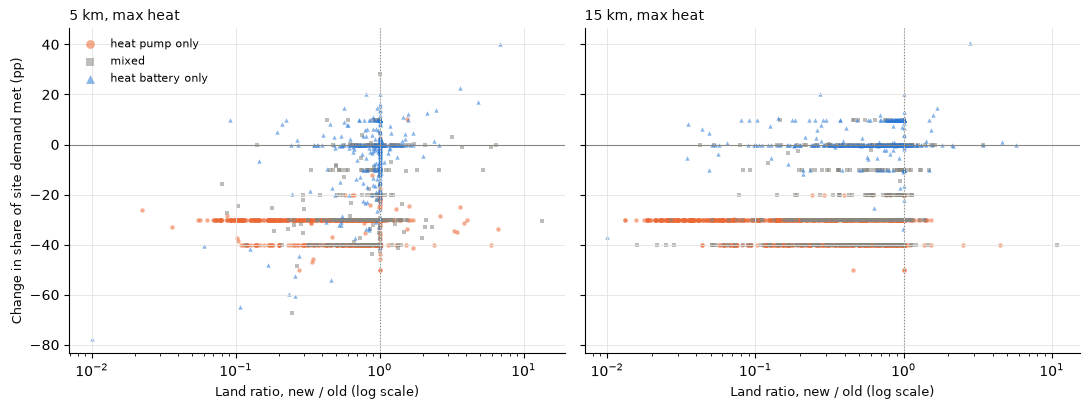

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, km in zip(axes, KMS):
    t = drivers(km, "heat")
    for route, c, mk in (("heat pump only", NEW_C, "o"), ("mixed", MUTED, "s"), ("heat battery only", OLD_C, "^")):
        s = t[t["route"] == route]
        ax.scatter(s["land_ratio"].clip(0.01, 20), 100 * (s["c_new"] - s["c_old"]), s=10, color=c, marker=mk,
                   alpha=0.55, linewidth=0, label=route)
    ax.set_xscale("log")
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.axvline(1, color=MUTED, lw=0.8, ls=":")
    ax.set_title(f"{km} km, max heat", fontsize=10, loc="left", color=INK)
    ax.set_xlabel("Land ratio, new / old (log scale)", fontsize=9, color=INK)
    ax.grid(color="#e4e3df", lw=0.6)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
axes[0].set_ylabel("Change in share of site demand met (pp)", fontsize=9, color=INK)
axes[0].legend(frameon=False, fontsize=8, markerscale=2)
fig.tight_layout()
plt.show()

In [12]:
# Per-sector view of the share-met effect, with land and route context (15 km and 5 km, both points)
for km in KMS:
    for tag, name in (("sav", "max savings"), ("heat", "max heat")):
        t = drivers(km, tag)
        s = summarise(t, "subsector")
        s["median_land_ratio"] = t.groupby("subsector")["land_ratio"].median()
        s["hp_share_old"] = t.groupby("subsector").apply(lambda x: (SITES["old"].set_index("source_id")["hp_share"].reindex(x.index) * x.replaceable_heat_mwh_th).sum() / x.replaceable_heat_mwh_th.sum(), include_groups=False)
        s["hp_share_new"] = t.groupby("subsector").apply(lambda x: (x.hp_share * x.replaceable_heat_mwh_th).sum() / x.replaceable_heat_mwh_th.sum(), include_groups=False)
        print(f"\n=== {km} km, {name}: by sector")
        display(s.sort_values("share_effect_TWh").round(2))


=== 5 km, max savings: by sector


,sites,demand_TWh,share_old_%,share_new_%,share_effect_TWh,land_binding_old_%dem,land_binding_new_%dem,Li-ion_h_old,Li-ion_h_new,IHB_h_old,IHB_h_new,median_land_ratio,hp_share_old,hp_share_new
subsector,,,,,,,,,,,,,,
food-beverage-tobacco,862,90.12,79.95,50.98,-26.10,1.85,0.10,14.21,4.0,15.01,20.00,1.00,0.94,0.91
textiles-leather-apparel,612,18.26,83.32,49.72,-6.14,0.52,0.90,14.74,4.0,NaN,NaN,0.63,1.00,1.00
chemicals,49,48.74,67.54,57.36,-4.97,22.94,44.19,13.94,4.0,14.35,20.00,0.98,0.32,0.32
iron-and-steel,112,117.99,37.75,34.96,-3.29,70.71,80.45,14.76,4.0,14.44,20.00,1.00,0.00,0.00
pulp-and-paper,76,11.79,71.37,44.62,-3.15,13.46,13.29,13.93,4.0,NaN,20.00,1.00,1.00,0.97
aluminum,28,10.21,58.64,42.76,-1.62,24.60,38.09,14.36,NaN,14.90,20.00,1.00,0.65,0.00
glass,148,35.41,70.63,69.34,-0.45,4.13,6.37,NaN,4.0,14.78,20.00,1.00,0.00,0.22
petrochemical-steam-cracking,36,126.89,29.70,29.89,0.23,94.17,92.92,NaN,NaN,8.16,7.63,1.00,0.00,0.00
lime,62,10.35,61.93,65.13,0.33,25.56,11.97,NaN,NaN,14.92,20.00,1.00,0.00,0.00



=== 5 km, max heat: by sector


,sites,demand_TWh,share_old_%,share_new_%,share_effect_TWh,land_binding_old_%dem,land_binding_new_%dem,Li-ion_h_old,Li-ion_h_new,IHB_h_old,IHB_h_new,median_land_ratio,hp_share_old,hp_share_new
subsector,,,,,,,,,,,,,,
food-beverage-tobacco,862,90.12,89.98,58.07,-28.76,9.52,5.27,16.87,4.0,16.67,20.00,1.00,0.94,0.91
chemicals,49,48.74,75.03,62.44,-6.14,69.12,76.88,16.86,4.0,15.88,20.00,0.98,0.32,0.32
textiles-leather-apparel,612,18.26,90.88,57.59,-6.08,5.62,3.32,16.00,4.0,NaN,NaN,0.63,1.00,1.00
iron-and-steel,112,117.99,40.79,36.74,-4.79,84.80,91.21,16.87,4.0,15.61,20.00,1.00,0.00,0.00
pulp-and-paper,76,11.79,80.64,49.59,-3.66,49.49,28.61,16.86,4.0,NaN,20.00,1.00,1.00,0.97
aluminum,28,10.21,65.60,45.37,-2.06,84.83,86.40,17.08,NaN,17.41,20.00,1.00,0.65,0.00
glass,148,35.41,81.41,77.89,-1.25,10.39,28.53,NaN,4.0,16.41,20.00,1.00,0.00,0.22
cement,197,64.56,78.26,76.92,-0.87,28.45,44.03,NaN,NaN,16.37,20.00,1.00,0.00,0.00
petrochemical-steam-cracking,36,126.89,30.07,30.16,0.13,98.04,98.47,NaN,NaN,8.16,6.35,1.00,0.00,0.00



=== 15 km, max savings: by sector


,sites,demand_TWh,share_old_%,share_new_%,share_effect_TWh,land_binding_old_%dem,land_binding_new_%dem,Li-ion_h_old,Li-ion_h_new,IHB_h_old,IHB_h_new,median_land_ratio,hp_share_old,hp_share_new
subsector,,,,,,,,,,,,,,
food-beverage-tobacco,868,90.44,80.52,51.24,-26.48,0.00,0.00,14.21,4.0,15.01,20.0,0.64,0.94,0.91
textiles-leather-apparel,612,18.26,83.56,49.88,-6.15,0.00,0.00,14.74,4.0,NaN,NaN,0.17,1.00,1.00
pulp-and-paper,79,12.22,74.27,44.74,-3.61,0.00,0.00,13.96,4.0,NaN,20.0,0.81,1.00,0.97
chemicals,49,48.74,72.26,67.79,-2.18,0.00,0.00,13.94,4.0,14.52,20.0,0.90,0.32,0.32
aluminum,28,10.21,73.80,67.68,-0.62,0.00,24.26,14.36,NaN,14.95,20.0,0.93,0.65,0.00
glass,148,35.41,71.17,71.28,0.04,0.00,0.00,NaN,4.0,14.78,20.0,0.76,0.00,0.22
lime,62,10.35,68.86,74.08,0.54,0.00,0.00,NaN,NaN,14.96,20.0,0.43,0.00,0.00
cement,198,65.06,74.27,78.80,2.94,0.41,1.57,NaN,NaN,14.94,20.0,0.89,0.00,0.00
iron-and-steel,112,117.99,67.43,71.30,4.57,11.89,18.34,14.76,4.0,14.76,20.0,0.83,0.00,0.00



=== 15 km, max heat: by sector


,sites,demand_TWh,share_old_%,share_new_%,share_effect_TWh,land_binding_old_%dem,land_binding_new_%dem,Li-ion_h_old,Li-ion_h_new,IHB_h_old,IHB_h_new,median_land_ratio,hp_share_old,hp_share_new
subsector,,,,,,,,,,,,,,
food-beverage-tobacco,868,90.44,90.74,58.38,-29.26,0.00,0.00,16.87,4.0,16.67,20.0,0.64,0.94,0.91
textiles-leather-apparel,612,18.26,91.07,57.92,-6.06,0.00,0.51,15.99,4.0,NaN,NaN,0.17,1.00,1.00
pulp-and-paper,79,12.22,85.49,50.06,-4.33,0.00,0.00,16.87,4.0,NaN,20.0,0.81,1.00,0.97
chemicals,49,48.74,84.62,78.35,-3.05,0.00,14.85,16.86,4.0,16.00,20.0,0.90,0.32,0.32
aluminum,28,10.21,84.99,75.23,-1.00,24.17,25.04,16.80,NaN,17.41,20.0,0.93,0.65,0.00
glass,148,35.41,82.42,81.31,-0.39,0.00,4.15,NaN,4.0,16.41,20.0,0.76,0.00,0.22
lime,62,10.35,82.11,84.30,0.23,11.63,2.44,NaN,NaN,16.42,20.0,0.43,0.00,0.00
cement,198,65.06,85.24,86.68,0.93,3.48,7.13,NaN,NaN,16.41,20.0,0.89,0.00,0.00
iron-and-steel,112,117.99,78.17,80.53,2.79,26.38,53.60,16.87,4.0,16.40,20.0,0.83,0.00,0.00


## Evidence from single-site tests (2026-11-14/15, 15 km)

These four sites were re-solved one change at a time, which separates the model changes that the fleet decomposition above cannot.

| Site | Change tested | Result |
|---|---|---|
| Arla Göteborg (SWE, heat pumps only, land and heat unchanged) | all cost changes (DEA heat pumps, PV loss), 16 rep days → linked year | LCOH at 10–50% rises from €34.6 to €36.2/MWh (+5%) |
| Arla Göteborg | storage discharge capped at the load | max heat 90% → 50%. Capped LCOH €58 at 50%, €169 at 60%, and 63% is the most it can serve |
| Pfeifer & Langen Lage (DEU food, land 18 → 194 km²) | storage cap | max heat 90% → 50% despite 11× more land |
| ArcelorMittal Duisburg (DEU steel, heat battery, land 61 → 13 km²) | shared buffers | max serve 91% → 73% (68% with the storage cap). LCOH below 70% unchanged (€39.7 → 39.9) |
| Sisecam Flat Glass (ITA, heat ×2.8, more heat in heat pump bands) | heat rebuild | LCOH at ≤60% falls €30.7 → €26.7 because more heat goes to heat pumps |